# Multivariate Regression Model: Student Performace Checker and Early Warning System.
Note: This notebook is explained in detail in README, please review it from there.

Importing required packages

In [1]:
#library to ignore unnecessary warning
import warnings

#libraries for data manipulation and maths calculation
import numpy as np
import pandas as pd

#libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

#scikit-learn preprocessing and pipeline libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

#scikit-learn regression models
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

#library for model serialization
import joblib

#visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
# Loading the dataset
DATA_PATH = "/home/natinaelboda/math_ml_datascienc/data_sets/students_performance_dataset.csv"
df = pd.read_csv(DATA_PATH)

print(f"Initial Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns\n")

# Inspecting missing values
# Here is issue of pandas treating "None" as missing values but
# "None" in Parent_Education_Level column is actual value
# meaning parent do not have official degree, or diploma or others
# so it should be handled
print("Missing values before fixing 'None' string:")
print(df.isnull().sum()[df.isnull().sum() > 0])


# Fixing issue of None: pandas reads the literal category "None" as NaN.
# So "None" should be restored as a valid text category in Parent_Education_Level.
df["Parent_Education_Level"] = df["Parent_Education_Level"].fillna("None")

# Verify there are zero missing values across the entire dataset
print(f"Total missing values remaining after fix: {df.isnull().sum().sum()}")

# Preview the first 5 rows
df.head()

Initial Dataset Shape: 5000 rows and 23 columns

Missing values before fixing 'None' string:
Parent_Education_Level    1025
dtype: int64
Total missing values remaining after fix: 0


,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
0,S1000,Omar,Williams,student0@university.com,Female,22,Mathematics,97.36,40.61,59.61,...,62.84,59.8865,F,10.3,Yes,No,Master's,Medium,1,5.9
1,S1001,Maria,Brown,student1@university.com,Male,18,Business,97.71,57.27,74.00,...,98.23,81.9170,B,27.1,No,No,High School,Low,4,4.3
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Engineering,99.52,41.84,63.85,...,91.22,67.7170,D,12.4,Yes,No,High School,Low,9,6.1
3,S1003,Omar,Williams,student3@university.com,Female,24,Engineering,90.38,45.65,44.44,...,55.48,51.6535,F,25.5,No,Yes,High School,Low,8,4.9
4,S1004,John,Smith,student4@university.com,Female,23,CS,59.41,53.13,61.77,...,87.43,71.4030,C,13.3,Yes,No,Master's,Medium,6,4.5


In [3]:
warnings.filterwarnings("ignore")

# Removing Personally Identifiable Information columns which are just ID columns
# Other than identifying the row(student), they don't have any importance for 
#model training so I'm dropping them immediatly
pii_columns = ["Student_ID", "First_Name", "Last_Name", "Email"]
df_clean = df.drop(columns=pii_columns)

print(f"Shape after removing 4 PII columns: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns\n")

# Separateing and displaying numeric vs. categorical columns to verify dataset richness
numeric_cols = df_clean.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df_clean.select_dtypes(include=["object"]).columns.tolist()

print(f"Numeric Columns ({len(numeric_cols)}): {numeric_cols}\n")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")

Shape after removing 4 PII columns: 5000 rows, 19 columns

Numeric Columns (12): ['Age', 'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Total_Score', 'Study_Hours_per_Week', 'Stress_Level (1-10)', 'Sleep_Hours_per_Night']

Categorical Columns (7): ['Gender', 'Department', 'Grade', 'Extracurricular_Activities', 'Internet_Access_at_Home', 'Parent_Education_Level', 'Family_Income_Level']


## Data Analysis & Visualizations
Before selecting final features or encoding categorical columns, visualizing the dataset to inspect linear correlations, variable distributions, and socioeconomic group differences.

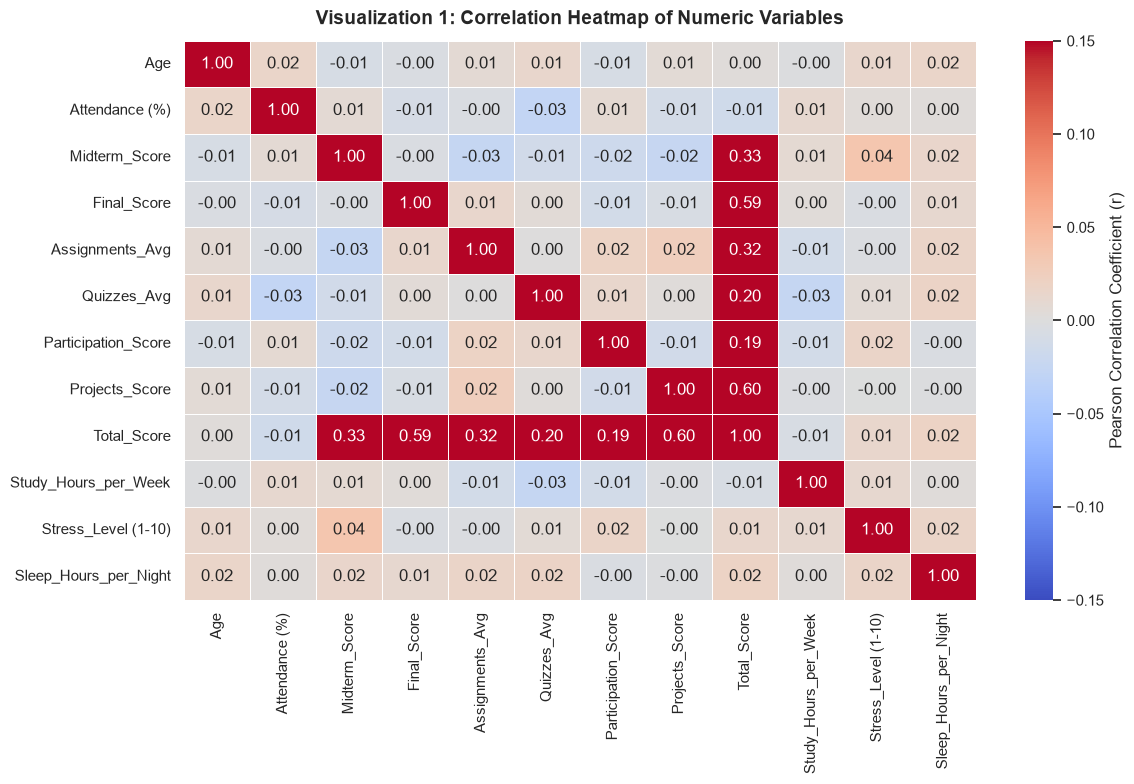

Exact correlation of numeric features with Total_Score:
Projects_Score           0.596076
Final_Score              0.588608
Midterm_Score            0.330636
Assignments_Avg          0.316676
Quizzes_Avg              0.201833
Participation_Score      0.187547
Sleep_Hours_per_Night    0.018847
Stress_Level (1-10)      0.013734
Age                      0.002746
Study_Hours_per_Week    -0.006609
Attendance (%)          -0.014165
Name: Total_Score, dtype: float64


In [4]:
# Calculating the Pearson correlation matrix for all 13 numeric columns
corr_matrix = df_clean[numeric_cols].corr()

# Plot the Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.15,
    vmax=0.15,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient (r)"}
)
plt.title("Visualization 1: Correlation Heatmap of Numeric Variables", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

# Printing exact correlations with the target variable (Total_Score) sorted by magnitude
print("Exact correlation of numeric features with Total_Score:")
print(corr_matrix["Total_Score"].drop("Total_Score").sort_values(ascending=False))

**What Visualization 1 Shows & Modelling Decision:**
This correlation heatmap displays the linear relationships ($r$) across all 13 numeric columns, including their correlation with target variable, `Total_Score`. From this correlation heatmap, we understand that `Age`, `Stress_Level (1-10)`, `Sleep_Hours_per_Night`, and `Study_Hours_per_Week` have near-zero linear correlation with `Total_Score`, and another thing is `Final_Score` representing result of final exam at the end of semester, can cause data leakage so I decide to drop it as well as (`Midterm_Score`, `Assignments_Avg`, `Projects_Score`, `Quizzes_Avg`, and `Attendance (%)`).

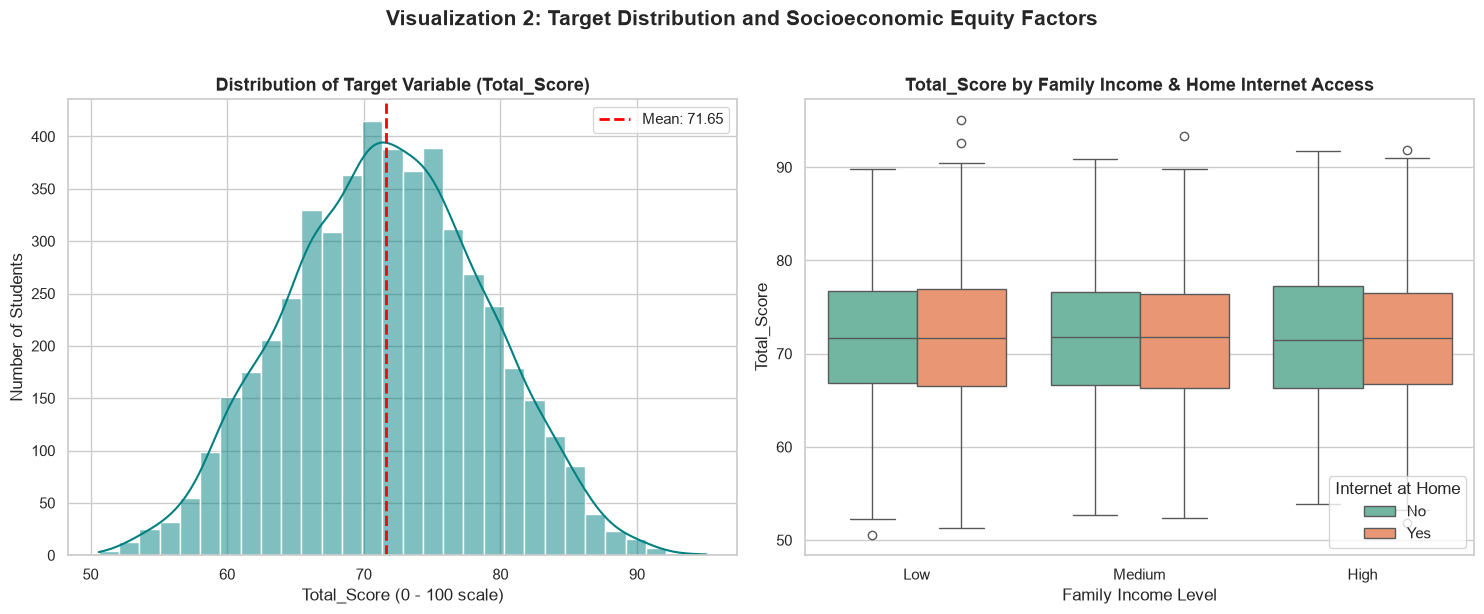

In [5]:
# Histogram of Target and Boxplot of Socioeconomic Categories
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Histogram and KDE of the target variable (Total_Score)
sns.histplot(df_clean["Total_Score"], bins=30, kde=True, color="teal", ax=axes[0])
axes[0].axvline(df_clean["Total_Score"].mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {df_clean['Total_Score'].mean():.2f}")
axes[0].set_title("Distribution of Target Variable (Total_Score)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Total_Score (0 - 100 scale)")
axes[0].set_ylabel("Number of Students")
axes[0].legend()

# Boxplot of Total_Score across Family Income Level and Internet Access
sns.boxplot(
    data=df_clean,
    x="Family_Income_Level",
    y="Total_Score",
    hue="Internet_Access_at_Home",
    order=["Low", "Medium", "High"],
    palette="Set2",
    ax=axes[1]
)
axes[1].set_title("Total_Score by Family Income & Home Internet Access", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Family Income Level")
axes[1].set_ylabel("Total_Score")
axes[1].legend(title="Internet at Home", loc="lower right")

plt.suptitle("Visualization 2: Target Distribution and Socioeconomic Equity Factors", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**What Visualization 2 Shows & Modelling Decision:**
The histogram on the left shows that `Total_Score` is distributed evenly bewteen minimum score of 50 and maximum score of 100 with its mean 71.65. Boxplot on the right shows how students' `Total_Score` varies across `Family_Income_Level` and `Internet_Access_at_Home`. I retain `Internet_Access_at_Home`, `Family_Income_Level`, and `Parent_Education_Level` as category features and later encode them.

## Feature Engineering: Selecting Features While Dropping unnecessary ones.
To prevent data leakage and make the model be able to efficient and effect for building Student Performance Checker system, and by carefully analysizing the visualization,  I drop the following columns:
1. **Personally Identifiable Information Columns (4 dropped — `Student_ID`, `First_Name`, `Last_Name`, `Email`)**
2. **Target Leakage Columns (2 dropped — `Final_Score`, `Grade`)**
3. **Near zero correlation columns with Target (8 dropped — `Age`, `Gender`, `Department`, `Extracurricular_Activities`, `Study_Hours_per_Week`, `Participation_Score`, `Stress_Level (1-10)`, `Sleep_Hours_per_Night`)**

**Retained Features (8 Total — 5 Numeric + 3 Categorical) & Target (`Total_Score`):**
* **Numeric Features (5):** `Attendance (%)`, `Midterm_Score`, `Assignments_Avg`, `Quizzes_Avg`, `Projects_Score`
* **Categorical Features (3):** `Internet_Access_at_Home`, `Family_Income_Level`, `Parent_Education_Level`
* **Target Variable ($y$):** `Total_Score`

In [6]:
# Defining 5 numeric features, 3 categorical features, and 1 continuous target
selected_numeric = [
    "Attendance (%)",
    "Midterm_Score",
    "Assignments_Avg",
    "Quizzes_Avg",
    "Projects_Score"
]

selected_categorical = [
    "Internet_Access_at_Home",
    "Family_Income_Level",
    "Parent_Education_Level"
]

feature_cols = selected_numeric + selected_categorical
target_col = "Total_Score"

# Create the feature matrix X (8 columns) and target vector y
X = df_clean[feature_cols].copy()
y = df_clean[target_col].copy()

print(f"Final Feature Matrix (X) Shape: {X.shape} (Rows, Columns)")
print(f"Target Vector (y) Shape: {y.shape}\n")
print("Selected Features and Data Types:")
print(X.dtypes)

Final Feature Matrix (X) Shape: (5000, 8) (Rows, Columns)
Target Vector (y) Shape: (5000,)

Selected Features and Data Types:
Attendance (%)             float64
Midterm_Score              float64
Assignments_Avg            float64
Quizzes_Avg                float64
Projects_Score             float64
Internet_Access_at_Home        str
Family_Income_Level            str
Parent_Education_Level         str
dtype: object


## Data Preprocessing: Categorical Encoding, Train/Test Split, and Standardization
1. **Ordinal Categorical Encoding:** Converting categorical columns (`Internet_Access_at_Home`, `Family_Income_Level`, `Parent_Education_Level`) into ordered numeric values (`0, 1, 2...`).
2. **Train/Test Split (80% train / 20% test):** Putting aside 20% (1,000 rows) as test set.
3. **Standardization (`StandardScaler`):** Fit the scaler **on the training set** (`X_train`).

In [7]:
# Definining 3 ordinal categorical columns
internet_categories = ["No", "Yes"]
income_categories = ["Low", "Medium", "High"]
education_categories = ["None", "High School", "Bachelor's", "Master's", "PhD"]

# Create an OrdinalEncoder with category order
ordinal_encoder = OrdinalEncoder(
    categories=[internet_categories, income_categories, education_categories],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

# Making a copy of X to show the explicit numeric conversion
X_encoded = X.copy()
X_encoded[selected_categorical] = ordinal_encoder.fit_transform(X[selected_categorical])

print("Categorical Encoding Mapping:")
for col, cats in zip(selected_categorical, ordinal_encoder.categories_):
    mapping = {cat: idx for idx, cat in enumerate(cats)}
    print(f"  - {col}: {mapping}")

print("\nPreview of X after converting categorical columns to numeric:")
X_encoded.head()

Categorical Encoding Mapping:
  - Internet_Access_at_Home: {'No': 0, 'Yes': 1}
  - Family_Income_Level: {'Low': 0, 'Medium': 1, 'High': 2}
  - Parent_Education_Level: {'None': 0, 'High School': 1, "Bachelor's": 2, "Master's": 3, 'PhD': 4}

Preview of X after converting categorical columns to numeric:


,Attendance (%),Midterm_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Internet_Access_at_Home,Family_Income_Level,Parent_Education_Level
0,97.36,40.61,73.69,53.17,62.84,0.0,1.0,3.0
1,97.71,57.27,74.23,98.23,98.23,0.0,0.0,1.0
2,99.52,41.84,85.85,50.00,91.22,0.0,0.0,1.0
3,90.38,45.65,68.10,66.27,55.48,1.0,0.0,1.0
4,59.41,53.13,67.66,83.98,87.43,0.0,1.0,3.0


In [8]:
# Spliting the encoded data into 80% Training (4,000 rows) and 20% Testing (1,000 rows)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42
)

print(f"Training Set Shape: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Testing Set Shape:  X_test  = {X_test.shape}, y_test  = {y_test.shape}\n")

# Initialize StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test set using the training set's mean and standard deviation
X_test_scaled = scaler.transform(X_test)

# Verifying standardization
train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_cols)
print("Verification of Standardized Training Features:")
train_scaled_df.describe().loc[["mean", "std"]].round(4)


Training Set Shape: X_train = (4000, 8), y_train = (4000,)
Testing Set Shape:  X_test  = (1000, 8), y_test  = (1000,)

Verification of Standardized Training Features:


,Attendance (%),Midterm_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Internet_Access_at_Home,Family_Income_Level,Parent_Education_Level
mean,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000
std,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001


In [9]:
# Keeping same 80/20 split with raw string categories so saved Pipeline
# can accept raw strings ("Yes", "Low", "Bachelor's") later to access model from FastAPI and Flutter
X_train_raw, X_test_raw, _, _ = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Define the reusable ColumnTransformer that encodes categoricals and scales all 8 features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), selected_numeric),
        ("cat", Pipeline([
            ("encode", OrdinalEncoder(
                categories=[internet_categories, income_categories, education_categories],
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )),
            ("scale", StandardScaler())
        ]), selected_categorical)
    ]
)

## Model Training, Hyperparameter Tuning, and Comparison
Training, Evaluating and Comparing four regression models on the same training and testing sets using **Mean Squared Error (MSE)**:
1. **`SGDRegressor` (Linear Regression via Stochastic Gradient Descent):** Tuned across multiple learning rates (`eta0`), regularization strengths (`alpha`), and numbers of epochs, then trained epoch-by-epoch using `partial_fit` to record and plot the train vs. test loss curve.
2. **`LinearRegression` (Closed-Form Ordinary Least Squares):** Computes the analytical optimal linear weights directly for baseline comparison.
3. **`DecisionTreeRegressor`:** A non-linear tree-based model tuned with `max_depth` to control overfitting.
4. **`RandomForestRegressor`:** An ensemble of decision trees that averages predictions across multiple trees to reduce variance.

In [16]:
# Hyperparameter Tuning for SGDRegressor
# Testing different combinations of learning rate (eta0), regularization (alpha), and epochs
learning_rates = [0.001, 0.01, 0.05]
alphas = [0.0001, 0.001, 0.01]
epoch_options = [50, 100, 150]

tuning_results = []
best_sgd_test_mse = float("inf")
best_sgd_params = {}

for lr in learning_rates:
    for alpha in alphas:
        for n_epochs in epoch_options:
            # Initialize SGDRegressor with max_iter=1 and warm_start=True for epoch control
            sgd_temp = SGDRegressor(
                learning_rate="invscaling",
                eta0=lr,
                alpha=alpha,
                penalty="l2",
                random_state=42
            )
            # Train across n_epochs using partial_fit
            rng = np.random.RandomState(42)
            for epoch in range(n_epochs):
                # Shuffle training data at each epoch for stochastic gradient descent
                indices = rng.permutation(len(X_train_scaled))
                sgd_temp.partial_fit(X_train_scaled[indices], y_train.iloc[indices])
            
            # Evaluate train and test MSE
            train_pred = sgd_temp.predict(X_train_scaled)
            test_pred = sgd_temp.predict(X_test_scaled)
            tr_mse = mean_squared_error(y_train, train_pred)
            te_mse = mean_squared_error(y_test, test_pred)
            
            tuning_results.append({
                "eta0 (Learning Rate)": lr,
                "alpha (Regularization)": alpha,
                "Epochs": n_epochs,
                "Train MSE": round(tr_mse, 4),
                "Test MSE": round(te_mse, 4)
            })
            
            if te_mse < best_sgd_test_mse:
                best_sgd_test_mse = te_mse
                best_sgd_params = {"eta0": lr, "alpha": alpha, "epochs": n_epochs}

tuning_df = pd.DataFrame(tuning_results).sort_values(by="Test MSE").reset_index(drop=True)
print("Top 5 SGDRegressor Hyperparameter Combinations (Sorted by Lowest Test MSE):")
print(tuning_df.head(5).to_string(index=False))
print(f"\nBest SGD Hyperparameters Selected: {best_sgd_params} (Test MSE: {best_sgd_test_mse:.4f})")

Top 5 SGDRegressor Hyperparameter Combinations (Sorted by Lowest Test MSE):
 eta0 (Learning Rate)  alpha (Regularization)  Epochs  Train MSE  Test MSE
                 0.01                  0.0010     150    19.9308   21.4350
                 0.01                  0.0001     150    19.9307   21.4350
                 0.01                  0.0100     150    19.9341   21.4374
                 0.01                  0.0001     100    19.9339   21.4398
                 0.01                  0.0010     100    19.9344   21.4402

Best SGD Hyperparameters Selected: {'eta0': 0.01, 'alpha': 0.001, 'epochs': 150} (Test MSE: 21.4350)


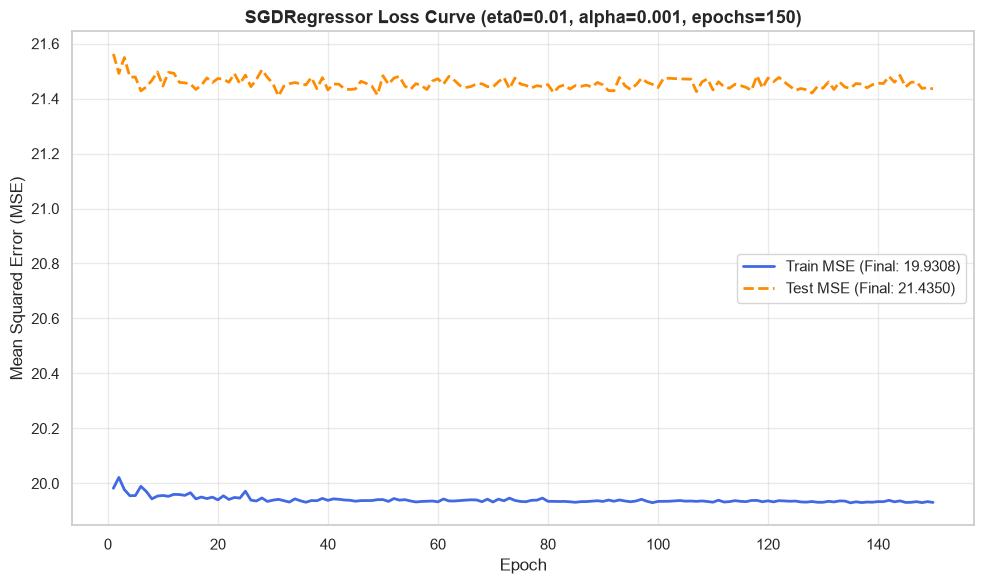

In [20]:
# Train the best SGDRegressor with partial_fit in a loop and record losses per epoch
best_lr = best_sgd_params["eta0"]
best_alpha = best_sgd_params["alpha"]
best_epochs = best_sgd_params["epochs"]

sgd_model = SGDRegressor(
    learning_rate="invscaling",
    eta0=best_lr,
    alpha=best_alpha,
    penalty="l2",
    random_state=42
)

train_mse_history = []
test_mse_history = []

rng = np.random.RandomState(42)
for epoch in range(best_epochs):
    indices = rng.permutation(len(X_train_scaled))
    sgd_model.partial_fit(X_train_scaled[indices], y_train.iloc[indices])
    
    # Record Train MSE and Test MSE at the end of each epoch
    y_train_pred_epoch = sgd_model.predict(X_train_scaled)
    y_test_pred_epoch = sgd_model.predict(X_test_scaled)
    
    train_mse_history.append(mean_squared_error(y_train, y_train_pred_epoch))
    test_mse_history.append(mean_squared_error(y_test, y_test_pred_epoch))

# Final MSE values for SGDRegressor
sgd_train_mse = train_mse_history[-1]
sgd_test_mse = test_mse_history[-1]

# REQUIRED PLOT 1: Plot Train MSE and Test MSE per epoch on one chart
plt.figure(figsize=(10, 6))
epochs_range = range(1, best_epochs + 1)
plt.plot(epochs_range, train_mse_history, label=f"Train MSE (Final: {sgd_train_mse:.4f})", color="royalblue", linewidth=2)
plt.plot(epochs_range, test_mse_history, label=f"Test MSE (Final: {sgd_test_mse:.4f})", color="darkorange", linestyle="--", linewidth=2)

plt.title(f"SGDRegressor Loss Curve (eta0={best_lr}, alpha={best_alpha}, epochs={best_epochs})", fontsize=13, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend(fontsize=11)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

**What the SGDRegressor Loss Curve Shows:**
The loss curve is showing change of both train and test MSE per epoch. As it can be understood from the plot, both MSE drop sharply for first few epochs then become nearly flat. This is expected behabiour as MSE makes big jump initially then smaller later.

In [24]:
# Training the other three models on the same standardized training set
# Model 2:LinearRegression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_train_mse = mean_squared_error(y_train, lr_model.predict(X_train_scaled))
lr_test_mse = mean_squared_error(y_test, lr_model.predict(X_test_scaled))

# Model 3: Decision Tree Regressor (tuned max_depth=5 to prevent extreme tree overfitting)
dt_model = DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=42)
dt_model.fit(X_train_scaled, y_train)
dt_train_mse = mean_squared_error(y_train, dt_model.predict(X_train_scaled))
dt_test_mse = mean_squared_error(y_test, dt_model.predict(X_test_scaled))

# Model 4: Random Forest Regressor (ensemble of 100 trees)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=6, min_samples_leaf=15, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
rf_train_mse = mean_squared_error(y_train, rf_model.predict(X_train_scaled))
rf_test_mse = mean_squared_error(y_test, rf_model.predict(X_test_scaled))

# comparison table of Train MSE and Test MSE for all four models
comparison_df = pd.DataFrame([
    {
        "Model": "Linear regression by gradient descent",
        "scikit-learn class": "SGDRegressor",
        "Train MSE": round(sgd_train_mse, 4),
        "Test MSE": round(sgd_test_mse, 4)
    },
    {
        "Model": "Linear regression",
        "scikit-learn class": "LinearRegression",
        "Train MSE": round(lr_train_mse, 4),
        "Test MSE": round(lr_test_mse, 4)
    },
    {
        "Model": "Decision tree",
        "scikit-learn class": "DecisionTreeRegressor",
        "Train MSE": round(dt_train_mse, 4),
        "Test MSE": round(dt_test_mse, 4)
    },
    {
        "Model": "Random forest",
        "scikit-learn class": "RandomForestRegressor",
        "Train MSE": round(rf_train_mse, 4),
        "Test MSE": round(rf_test_mse, 4)
    }
]).sort_values(by="Test MSE").reset_index(drop=True)

print("Model Comparison Table (Sorted by Lowest Test MSE)")
print(comparison_df.to_string(index=False))

best_model_name = comparison_df.loc[0, "Model"]
best_model_class = comparison_df.loc[0, "scikit-learn class"]
best_model_mse = comparison_df.loc[0, "Test MSE"]
print(f"\nBest Model (Lowest Test MSE): {best_model_name} ({best_model_class}) with Test MSE = {best_model_mse:.4f}")

Model Comparison Table (Sorted by Lowest Test MSE)
                                Model    scikit-learn class  Train MSE  Test MSE
Linear regression by gradient descent          SGDRegressor    19.9308   21.4350
                    Linear regression      LinearRegression    19.9288   21.4447
                        Random forest RandomForestRegressor    18.0287   22.8017
                        Decision tree DecisionTreeRegressor    22.2151   27.8774

Best Model (Lowest Test MSE): Linear regression by gradient descent (SGDRegressor) with Test MSE = 21.4350


**Best Model Selection & Justification:**
Based on the comparison table above, the model with the lowest Test MSE is selected as (`best_model_class`). As we can see clearly, Linear models (`SGDRegressor` and `LinearRegression`) and Random Forest (`RandomForestRegressor`) are better than `DecisionTreeRegressor`.

## Most Correlated Feature vs. Target (Before & After Fitted Line)
To visualize how linear regression fits a trend line to the data, a single feature with the strongest correlation to `Total_Score` is identified, then plot the **Before** scatter plot, and then fit a one-feature `LinearRegression` model on that feature to overlay the fitted regression line (**After**).

Feature having strongest correlation with the target: 'Projects_Score' (Pearson r = 0.5961)


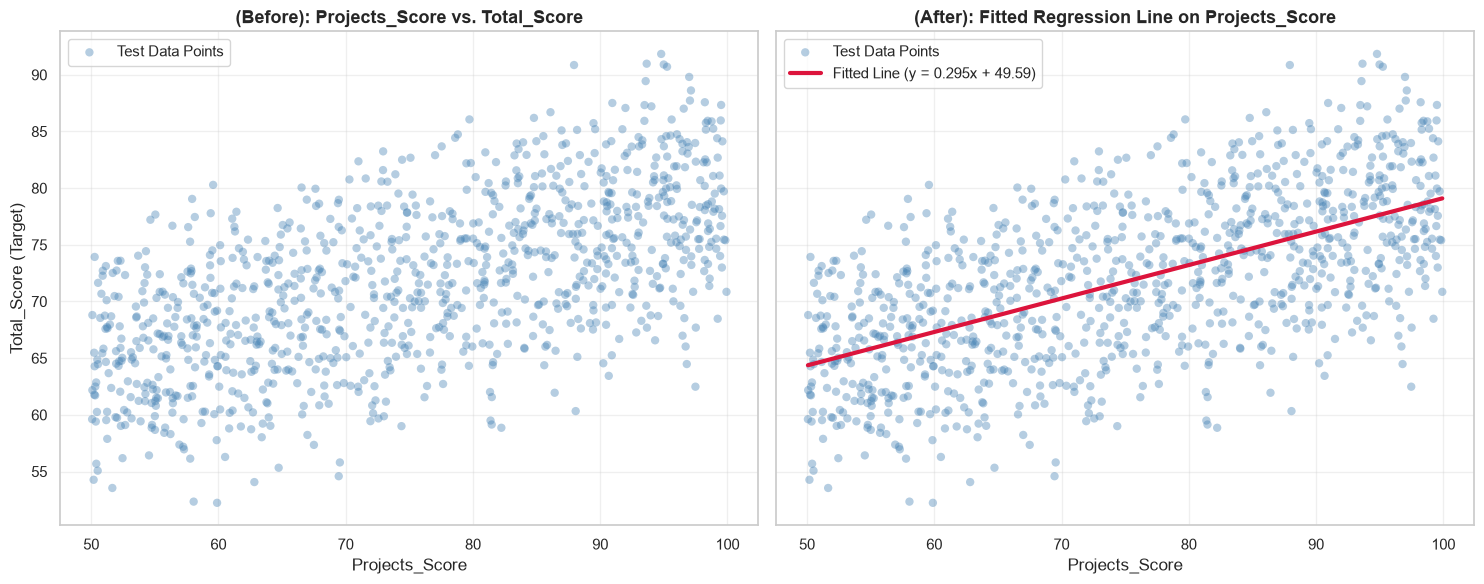

In [22]:
# Find the feature having strongest correlation with the target.
feature_correlations = X_encoded.apply(lambda col: col.corr(y)).abs().sort_values(ascending=False)
top_feature = feature_correlations.index[0]
top_corr_val = X_encoded[top_feature].corr(y)

print(f"Feature having strongest correlation with the target: '{top_feature}' (Pearson r = {top_corr_val:.4f})")

# Extract the feature from the training and testing sets
X_train_single = X_train[[top_feature]]
X_test_single = X_test[[top_feature]]

# Fit a one-feature LinearRegression model
single_feature_lr = LinearRegression()
single_feature_lr.fit(X_train_single, y_train)

# Generate X values across the feature's range to draw a regression line
x_line = np.linspace(X_test_single[top_feature].min(), X_test_single[top_feature].max(), 200).reshape(-1, 1)
y_line = single_feature_lr.predict(pd.DataFrame(x_line, columns=[top_feature]))

# (Scatter Before) and (Scatter After)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Scatter Plot, BEFORE
axes[0].scatter(X_test_single[top_feature], y_test, alpha=0.4, color="steelblue", edgecolors="none", label="Test Data Points")
axes[0].set_title(f"(Before): {top_feature} vs. Total_Score", fontsize=13, fontweight="bold")
axes[0].set_xlabel(top_feature)
axes[0].set_ylabel("Total_Score (Target)")
axes[0].legend(loc="upper left")
axes[0].grid(True, alpha=0.3)

# Scatter Plot, AFTER (with fitted regression line)
axes[1].scatter(X_test_single[top_feature], y_test, alpha=0.4, color="steelblue", edgecolors="none", label="Test Data Points")
axes[1].plot(
    x_line,
    y_line,
    color="crimson",
    linewidth=3,
    label=f"Fitted Line (y = {single_feature_lr.coef_[0]:.3f}x + {single_feature_lr.intercept_:.2f})"
)
axes[1].set_title(f"(After): Fitted Regression Line on {top_feature}", fontsize=13, fontweight="bold")
axes[1].set_xlabel(top_feature)
axes[1].legend(loc="upper left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**What the the before and after Scatter Plots Show:**
The left plot (**Before**) displays the raw scatter distribution of the most correlated feature(which is "Project_Score" against `Total_Score` on the test set. The right plot (**After**) overlays the fitted one-feature line. 

## Saving the Best Model Pipeline and Predicting on a Single Test Row
Previously, `ColumnTransformer` which is the one that preprocesses when new row arrives from(user) FlutterApp, it is and best model(`SGDRegressor`) is saved to scikit-learn `Pipeline`.
* Save the pipeline to both `best_model.pkl` (in the current directory) and `../API/best_model.pkl` so the FastAPI service in Task 2 can load it directly.
* THen writing function `predict_single_student()` that loads the saved `.pkl` file and predicts `Total_Score` for one row of the test set.

In [30]:
import os
from pathlib import Path

# Mapping the 4 model class names to fresh instances configured with best hyperparameters
model_candidates = {
    "SGDRegressor": SGDRegressor(
        learning_rate="invscaling",
        eta0=best_sgd_params["eta0"],
        alpha=best_sgd_params["alpha"],
        penalty="l2",
        max_iter=best_sgd_params["epochs"],
        random_state=42
    ),
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=42),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=100, max_depth=6, min_samples_leaf=15, random_state=42, n_jobs=-1)
}

# Select the best one with the lowest Test MSE
winning_estimator = model_candidates[best_model_class]
print(f"Building full Pipeline with best model: {best_model_name} ({best_model_class})")

# Combine the preprocessor and the best model into one Pipeline
best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", winning_estimator)
])

# Fit the pipeline on the raw training data (X_train_raw contains original text strings like "Yes", "Low")
best_pipeline.fit(X_train_raw, y_train)

# Verify the pipeline's Test MSE matches the comparison table
pipeline_test_preds = best_pipeline.predict(X_test_raw)
pipeline_test_mse = mean_squared_error(y_test, pipeline_test_preds)
print(f"Pipeline Test MSE: {pipeline_test_mse:.4f}")

# One path used for both saving and loading: summative/API/best_model.pkl
# (the notebook must be run from the linear_regression folder)
api_dir = Path("..") / "API"
api_dir.mkdir(parents=True, exist_ok=True)   # creates the API folder if it is missing
MODEL_PATH = api_dir / "best_model.pkl"

joblib.dump(best_pipeline, MODEL_PATH)
print(f"Saved winning pipeline to: {MODEL_PATH.resolve()}")


# Reusable function that loads the saved model and predicts for one row
def predict_single_student(input_data: dict, model_path=MODEL_PATH) -> float:
    """
    Loads the saved scikit-learn Pipeline from disk and predicts Total_Score
    for a single student.
    """
    loaded_pipeline = joblib.load(model_path)
    input_df = pd.DataFrame([input_data])
    predicted_score = loaded_pipeline.predict(input_df)[0]
    return float(round(predicted_score, 2))


# Test the function on the first row of the test set
sample_row_dict = X_test_raw.iloc[0].to_dict()
actual_score = float(y_test.iloc[0])
predicted_score = predict_single_student(sample_row_dict)

print("\nSingle Test Row Prediction Verification")
print("Input Features for Test Student:")
for k, v in sample_row_dict.items():
    print(f"  {k}: {v}")
print(f"\nActual Total_Score:    {actual_score:.2f}")
print(f"Predicted Total_Score: {predicted_score:.2f}")
print(f"Absolute Difference:   {abs(actual_score - predicted_score):.2f}")

Building full Pipeline with best model: Linear regression by gradient descent (SGDRegressor)
Pipeline Test MSE: 21.4809
Saved winning pipeline to: /home/natinaelboda/linear_regression_model/summative/API/best_model.pkl

Single Test Row Prediction Verification
Input Features for Test Student:
  Attendance (%): 52.39
  Midterm_Score: 65.44
  Assignments_Avg: 66.19
  Quizzes_Avg: 69.06
  Projects_Score: 54.06
  Internet_Access_at_Home: No
  Family_Income_Level: Low
  Parent_Education_Level: PhD

Actual Total_Score:    67.81
Predicted Total_Score: 62.81
Absolute Difference:   5.00
